In [2]:
!pip install charset_normalizer


In [1]:
# Core Libraries
import numpy as np
import pandas as pd
import re
import random

# PyTorch Core
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Keras Tokenizer (for vocab + padding)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import classification_report, accuracy_score, roc_curve, auc
from sklearn.utils import resample
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier

# Plotting
import matplotlib.pyplot as plt
from itertools import cycle

# NLP
import nltk
from nltk.stem.snowball import SnowballStemmer

# Optional: Progress Bar
from tqdm import tqdm

# Transformers (optional if using BERT later)
from transformers import AutoModel
from transformers import AutoTokenizer


C:\Users\Administrator\anaconda3\envs\pytorchCU126_py310_new\lib\site-packages\requests\__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


C:\Users\Administrator\anaconda3\envs\pytorchCU126_py310_new\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [77]:
import re
from nltk.tokenize import word_tokenize

# Bengali stopwords (offline-safe)
bengali_stopwords = {
    "অনেক", "অন্য", "অবশ্য", "আগে", "আছে", "আজ", "আবার", "আমরা", "আমাদের", "আর",
    "ই", "উত্তর", "উপর", "উপরে", "এ", "এই", "এক্", "এখন", "এত", "এব", "এমন", "এমনি",
    "এর", "এস", "এসে", "ও", "ওই", "কমনে", "করা", "করে", "কাছে", "কাজ", "কাজে", "কারণ",
    "কি", "কিছু", "কে", "কেউ", "কেখা", "কেন", "কোটি", "কোনো", "কয়েক", "খুব", "গিয়ে",
    "গেল", "চার", "চালু", "চেষ্টা", "ছিল", "জানা", "জ্নজন", "টি", "তখন", "তবে", "তা",
    "তাই", "তো", "থাকা", "থেকে", "দিন", "দু", "দুই", "দেওয়া", "ধামার", "নতুন", "না",
    "নাগাদ", "নিয়ে", "নেওয়া", "নয়", "পর", "পরে", "পাচ", "পি", "পেয়্র্", "প্রতি", "প্রথম",
    "প্রযন্ত", "প্রাথমিক", "প্রায়", "বক্তব্য", "বন", "বলা", "বলে", "বলেন", "বহু", "বা",
    "বি", "বিভিন্ন", "বেশ", "বেশি", "মতো", "মধ্যে", "মনে", "যখন", "যদি", "যা", "যাওয়া",
    "যে", "র", "রকম", "লক্ষ", "শুধু", "শুরু", "সঙ্গে", "সব", "সহ", "সাধারণ", "সামনে",
    "সি", "সে", "সেই", "হতে", "হাজার", "হয়", "এই", "ও", "থেকে", "করে", "এ", "না", "ওই",
    "এক্", "নিয়ে", "করা", "বলেন", "সঙ্গে", "যে", "এব", "তা", "আর", "কোনো", "বলে", "সেই",
    "দিন", "হয়", "কি", "দু", "পরে", "সব", "দেওয়া", "মধ্যে", "এর", "সি", "শুরু", "কাজ",
    "কিছু", "কাছে", "সে", "তবে", "বা", "বন", "আগে", "জ্নজন", "পি", "পর", "তো", "ছিল",
    "এখন", "আমরা", "প্রায়", "দুই", "আমাদের", "তাই", "অন্য", "গিয়ে", "প্রযন্ত", "মনে",
    "নতুন", "মতো", "কেখা", "প্রথম", "আজ", "টি", "ধামার", "অনেক", "বিভিন্ন", "র", "হাজার",
    "জানা", "নয়", "অবশ্য", "বেশি", "এস", "করে", "কে", "হতে", "বি", "কয়েক", "সহ", "বেশ",
    "এমন", "এমনি", "কেন", "কেউ", "নেওয়া", "চেষ্টা", "লক্ষ", "বলা", "কারণ", "আছে", "শুধু",
    "তখন", "যা", "এসে", "চার", "ছিল", "যদি", "আবার", "কোটি", "উত্তর", "সামনে", "উপর",
    "বক্তব্য", "এত", "প্রাথমিক", "উপরে", "আছে", "প্রতি", "কাজে", "যখন", "খুব", "বহু",
    "গেল", "পেয়্র্", "চালু", "ই", "নাগাদ", "থাকা", "পাচ", "যাওয়া", "রকম", "সাধারণ", "কমনে",
    "অবশ্য", "অনেক", "অনেকে", "অনেকেই", "অন্তত", "অথবা", "অথচ", "অর্থাত", "অন্য", "আজ",
    "আছে", "আপনার", "আপনি", "আবার", "আমরা", "আমাকে", "আমাদের", "আমার", "আমি", "আরও",
    "আর", "আগে", "আগেই", "আই", "অতএব", "আগামী", "অবধি", "অনুযায়ী", "আদ্যভাগে", "এই",
    "একই", "একে", "একটি", "এখন", "এখনও", "এখানে", "এখানেই", "এটি", "এটা", "এটাই",
    "এতটাই", "এবং", "একবার", "এবার", "এদের", "এঁদের", "এমন", "এমনকী", "এল", "এর", "এরা",
    "এঁরা", "এস", "এত", "এতে", "এসে", "একে", "এ", "ঐ", "ই", "ইহা", "ইত্যাদি", "উনি", "উপর",
    "উপরে", "উচিত", "ও", "ওই", "ওর", "ওরা", "ওঁর", "ওঁরা", "ওকে", "ওদের", "ওঁদের", "ওখানে",
    "কত", "কবে", "করতে", "কয়েক", "কয়েকটি", "করবে", "করলেন", "করার", "কারও", "করা",
    "করি", "করিয়ে", "করার", "করাই", "করলে", "করলেন", "করিতে", "করিয়া", "করেছিলেন",
    "করছে", "করছেন", "করেছেন", "করেছে", "করেন", "করবেন", "করায়", "করে", "করেই", "কাছ",
    "কাছে", "কাজে", "কারণ", "কিছু", "কিছুই", "কিন্তু", "কিংবা", "কি", "কী", "কেউ",
    "কেউই", "কাউকে", "কেন", "কে", "কোনও", "কোনো", "কোন", "কখনও", "ক্ষেত্রে", "খুব",
    "গুলি", "গিয়ে", "গিয়েছে", "গেছে", "গেল", "গেলে", "গোটা", "চলে", "ছাড়া", "ছাড়াও",
    "ছিলেন", "ছিল", "জন্য", "জানা", "ঠিক", "তিনি", "তিনঐ", "তিনিও", "তখন", "তবে", "তবু",
    "তাঁদের", "তাঁাহারা", "তাঁরা", "তাঁর", "তাঁকে", "তাই", "তেমন", "তাকে", "তাহা", "তাহাতে",
    "তাহার", "তাদের", "তারপর", "তারা", "তারৈ", "তার", "তাহলে", "তিনি", "তা", "তাও", "তাতে",
    "তো", "তত", "তুমি", "তোমার", "তথা", "থাকে", "থাকা", "থাকায়", "থেকে", "থেকেও", "থাকবে",
    "থাকেন", "থাকবেন", "থেকেই", "দিকে", "দিতে", "দিয়ে", "দিয়েছে", "দিয়েছেন", "দিলেন",
    "দু", "দুটি", "দুটো", "দেয়", "দেওয়া", "দেওয়ার", "দেখা", "দেখে", "দেখতে", "দ্বারা",
    "ধরে", "ধরা", "নয়", "নানা", "না", "নাকি", "নাগাদ", "নিতে", "নিজে", "নিজেই", "নিজের",
    "নিজেদের", "নিয়ে", "নেওয়া", "নেওয়ার", "নেই", "নাই", "পক্ষে", "পর্যন্ত", "পাওয়া",
    "পারেন", "পারি", "পারে", "পরে", "পরেই", "পরেও", "পর", "পেয়ে", "প্রতি", "প্রভৃতি",
    "প্রায়", "ফের", "ফলে", "ফিরে", "ব্যবহার", "বলতে", "বললেন", "বলেছেন", "বলল", "বলা",
    "বলেন", "বলে", "বহু", "বসে", "বার", "বা", "বিনা", "বরং", "বদলে", "বাদে", "বার", "বিশেষ",
    "বিভিন্ন", "বিষয়টি", "ব্যবহার", "ব্যাপারে", "ভাবে", "ভাবেই", "মধ্যে", "মধ্যেই",
    "মধ্যেও", "মধ্যভাগে", "মাধ্যমে", "মাত্র", "মতো", "মতোই", "মোটেই", "যখন", "যদি",
    "যদিও", "যাবে", "যায়", "যাকে", "যাওয়া", "যাওয়ার", "যত", "যতটা", "যা", "যার", "যারা",
    "যাঁর", "যাঁরা", "যাদের", "যান", "যাচ্ছে", "যেতে", "যাতে", "যেন", "যেমন", "যেখানে",
    "যিনি", "যে", "রেখে", "রাখা", "রয়েছে", "রকম", "শুধু", "সঙ্গে", "সঙ্গেও", "সমস্ত",
    "সব", "সবার", "সহ", "সুতরাং", "সহিত", "সেই", "সেটা", "সেটি", "সেটাই", "সেটাও",
    "সম্প্রতি", "সেখান", "সেখানে", "সে", "স্পষ্ট", "স্বয়ং", "হইতে", "হইবে", "হৈলে",
    "হইয়া", "হচ্ছে", "হত", "হতে", "হতেই", "হবে", "হবেন", "হয়েছিল", "হয়েছে", "হয়েছেন",
    "হয়ে", "হয়নি", "হয়", "হয়েই", "হয়তো", "হল", "হলে", "হলেই", "হলেও", "হলো", "হিসাবে",
    "হওয়া", "হওয়ার", "হওয়ায়", "হন", "হোক", "জন", "জনকে", "জনের", "জানতে", "জানায়",
    "জানিয়ে", "জানানো", "জানিয়েছে", "জন্য", "জন্যওজে", "জে", "বেশ", "দেন", "তুলে",
    "ছিলেন", "চান", "চায়", "চেয়ে", "মোট", "যথেষ্ট", "টি"
}

bn_sw = bengali_stopwords

# Rule-based pseudo stemmer
def basic_bengali_stemmer(word):
    suffixes = [
        'গুলো', 'গুলি', 'টাকে', 'টিতে', 'টায়', 'টা', 'টি',
        'দেরকে', 'দের', 'গুলোকে', 'কে', 'তে', 'তা', 'ের', 'েন',
        'ছি', 'ছিল', 'বেন', 'েছ', 'ে', 'রা', 'য়'
    ]
    for suffix in suffixes:
        if word.endswith(suffix) and len(word) > len(suffix) + 1:
            return word[:-len(suffix)]
    return word

# Cleaning functions
def remove_url(text):
    return re.sub(r"(?:\@|https?\://)\S+", "", text) if isinstance(text, str) else ''

def remove_numbers(text):
    return re.sub(r'\d+', '', text) if isinstance(text, str) else ''

def remove_english(text):
    return re.sub(r'[a-z]', '', text) if isinstance(text, str) else ''

def remove_short_words(text, min_len=2):
    if not isinstance(text, str):
        return ''
    return ' '.join([word for word in text.split() if len(word) >= min_len])

def remove_repeated_punctuation(text):
    return re.sub(r'[\?\.\!\।]+(?=[\?\.\!\।])', '', text) if isinstance(text, str) else ''

def remove_extra_whitespace(text):
    return ' '.join(text.split()) if isinstance(text, str) else ''

def remove_dari(text):
    return re.sub(r'।', '', text) if isinstance(text, str) else ''

def remove_bengali_stopwords(text):
    if not isinstance(text, str):
        return ''
    return ' '.join([word for word in text.split() if word not in bengali_stopwords])

# Final cleaner
def clean_comment(text):
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = remove_url(text)
    text = remove_english(text)
    text = remove_dari(text)
    text = remove_numbers(text)
    text = remove_short_words(text)
    text = remove_repeated_punctuation(text)
    text = remove_extra_whitespace(text)
    words = text.split()
    # Remove stopwords and apply stemming
    cleaned = [basic_bengali_stemmer(word) for word in words if word not in bengali_stopwords]
    return ' '.join(cleaned)

In [78]:
# Define positive Bengali words
positive_words = {
    "অসাধারণ", "দারুণ", "চমৎকার", "অবিশ্বাস্য", "সুন্দর", "অত্যন্ত ভালো", "অভিনন্দন", "শ্রদ্ধা", "প্রশংসনীয়", "মুগ্ধ",
    "দারুণ কাজ", "ভালোবাসা", "অনন্য", "সেরা", "জয় হোক", "অনবদ্য", "অপূর্ব", "অতুলনীয়", "আকর্ষণীয়", "অনিন্দ্য",
    "উজ্জ্বল", "উচ্ছ্বাস", "উত্তম", "উত্সাহজনক", "উজ্জীবিত", "উন্নত", "একেবারে অসাধারণ", "একান্ত ভালো", "আনন্দদায়ক",
    "আশ্চর্যজনক", "আশার আলো", "অর্জন", "আলোকিত", "আশা জাগানো", "কৃতজ্ঞতা", "খাঁটি", "খুশি", "গর্বিত", "গুণগত",
    "গৌরবজনক", "যথার্থ", "চিত্তাকর্ষক", "জয়ী", "দৃঢ়", "দীপ্ত", "দৃষ্টিনন্দন", "দয়ালু", "নান্দনিক", "নিখুঁত",
    "নিবেদিত", "প্রশান্তি", "প্রশস্ত", "প্রেরণাদায়ক", "ফলপ্রসূ", "বেড়ে চলা", "মহৎ", "মনোমুগ্ধকর", "মধুর", "মিষ্টি",
    "মজাদার", "মহান", "মার্জিত", "রহস্যময়", "লোভনীয়", "লাবণ্য", "শ্রেষ্ঠ", "স্বপ্নিল", "স্বর্ণালী", "স্নিগ্ধ",
    "সৃষ্টিশীল", "স্মরণীয়", "সমৃদ্ধ", "সাবলীল", "সত্য", "হৃদয়স্পর্শী", "হালকা", "হীরক", "হিরণ্ময়", "হংস"
}
negative_words = {
    # Religious Hate
    "মন্দির ভাঙো", "মসজিদ ধ্বংস", "জিহাদ", "কাফের", "ধর্মান্তর", "পূজা বন্ধ",
    "ধর্মের অপমান", "নাস্তিক", "ধর্মদ্রোহী", "খ্রিস্টান কুকুর", "হিন্দু কুকুর",
    "বৌদ্ধ নষ্ট", "ধর্ম যুদ্ধ", "ধর্মের শত্রু", "ধর্মের নামে হিংসা", "মুসলিম কুকুর",
    "ধর্ম ছাড়", "পাপী", "নরকগামী",  
    # General Hate/Abuse
    "গালি", "অপমান", "ঘৃণা", "শত্রু", "মারধর", "খুন", "জল্লাদ", "হত্যা", "ধর্ষণ",
    "নষ্ট", "কুত্তার বাচ্চা", "হারামি", "বেশ্যা", "অসভ্য", "নিচ", "জঘন্য", "পাষণ্ড",
    "অপদার্থ", "নরাধম", "কম্বক্ত", "গাধা", "মূর্খ", "পাজি", "অধম", "শয়তান", "চোর",
    "বদমাশ", "অপকর্মী",  
    # Threats/Violence
    "মেরে ফেলব", "খুন করব", "পিটিয়ে মারব", "জ্যান্ত পুড়িয়ে মারব", "ঘর থেকে তাড়াব",
    "ধরাশায়ী করব", "রক্ত ঝরাব", "বোমা মারব", "গলা কাটব", "পাথর মারব", "জীবন নষ্ট করব",
    "মাথা ফাটব", "হাড় ভাঙব", "চোখ তুলব",  
    # Gender/Caste Slurs
    "দলিত কুকুর", "নীচ জাত", "মেয়েলি গালি", "স্ত্রীজাত", "অস্পৃশ্য", "জাত খারাপ",
    "কুলটা", "রাঁড়", "বেশ্যার পুত্র", "হরিজন", "জাতিচ্যুত", "গোয়ালার বাচ্চা",
    "চামার",  
    # Sexual/Explicit Content
    "যৌন", "অশ্লীল", "গুদা", "চোদা", "ভোগ", "ধোন", "মাই চুষ", "বস্তা", "মাগি",
    "খানকি",  
    # Cyberbullying/Trolling
    "মর বাচ্চা", "বোকাচোদা", "টিটকারি", "তোর বাপের ব্যাটা", "খান্কি মাগি",
    "বুদ্ধি নষ্ট", "মুখে থু", "লান্ড চুষ", "চোদনা", "হাঁড়িচ্যাটা",
    "শুয়োরের বাচ্চা", "কুত্তার বাচ্ছা", "হারামির বাচ্চা", "হারামি", "হারামজাদা", "হারামখোর", 
    "খাঙ্কিরপোলা", "খান্কি মাগির পোলা", "চোদনা", "চুদির ভাই", "চুতমারানি", "চুদির পোলা", 
    "তর মায়রে চুদি", "তর মায়রে বাপ", "শালা", "শালার পো শালা", "হুমুন্দির পুত", "মাঙ্গির পুত", 
    "নাটকির পো", "ল্যাউড়ার পুত", "হাউয়ার পো", "হাউয়ার নাতি", "চুদানির পো", "ভুদার বেটা", 
    "লটির পো", "লটির বেটা", "ভেড়াচ্চোদা", "মাউড়া চোদা", "গুয়ার ভিতরে ভইড়া দিমু", 
    "হোগার ভিতরে ভইড়া দিমু", "ঠ্যাঁঙ কাইট্টা পুটকি দা ভইরা দুম!", "হালা ল্যাওড়া চোদা", "বানচোত", 
    "কুত্তাচোদা", "তর পুটকিত ধান ছড়াইয়া চড়ুই দিয়া খাওয়ামু", "পুটকি", "বালি দিয়া চুদমু তরে খাঙ্কি মাগী!", 
    "চুদমু", "বালের রয়েল বেঙ্গল উকুন", "বাল", "তোর হউরিরে ডিগবাজী", "ছি ছি ছি", 
    "তোর জাঙ্গীয়া খুইল্যা আগুন লাগায় দিমু", "বাল ফালায়া খালে নামানো", "বাল ফালায়া আটিঁ বান্ধা", 
    "বালে বালে গিট্টু", "গোলাম আযম", "মইত্যা নিজামী", "গেলমান", "তিনকোনা", "চতুরচোর", 
    "মহাবুবস্", "বাপের আগে বাল ফালায়", "ভোদাই", "ভোদার বাল", "বাল", "বাল ছাল", "ধোনের বাল",
    "ধোন", "হোল", "টেংরি ভাইংগা হাতে ধরায়া দিমু", "নটি", "নটি মাগি", "মাগি", "নটি মাগির পোলা", 
    "নটি মাগির ঝি", "গুদের বাল", "মাগিবাজ", "মাইগ্যা", "বারবাতারি", "বেশ্যা", "বেশ্যা মাগী", 
    "বাল ফালাইয়া আটি বান", "ভৈরব মাগী", "পুকটি মারা খা", "পুকটি", "পুক্টি", "গাড় মারা খা", 
    "ভইরা দিমু", "মাঙ্গের পোলা", "উপ্তা কইরা চুদমু", "মাঙ্গের নাতি", "চুদনা মাগী", "ভাতার চুদা", 
    "মীরজাফর", "নীজামী", "উপ্তা কইরা চুদা দিমু", "গোস্তের লাঠি সাটামু", "ধোন কাইট্টা কুত্তা দিয়া খাওয়ামু", 
    "কুত্তা", "কুত্তার বাচ্চা", "লেওরা", "নিবীর্জ", "চুতমারানীর পোলা", "তর মায়েরে চিচিং ফাক", "কান্দে ফালাইয়া তর মায়েরে চুদি", "পুটকিতে বাশ দিমু", "চামড়া ছুইল্লা লবণ লাগামু", "লাথ্থি দিমু", "উষ্টা খা", "সুদখোর", "গুদির ব্যাটা", "কাঠ্ঠির বেট্যা", "ল্যাদানী", "হোলচাটা", "মাহফুজ সাহেব", "বাইনচোদ", "মাদার চোদ", "হোগা চাটা", "নিজামী চোদা", "মুজাহিদের বউ", "বটই", "পেল", "গো আর জুতা", "শাউয়া", "কুত্তার হোল", "হোল টাইনা পুকটিতে ভর", "হোলের চুলকানী", "আবাল চোদা", "চোদ", "বোকা আচোদা", "খবিশ চোদা", "খবিশ", "ভুস্কি মাগির পোলা", "তর ভোদায় বিলাই হ্যাচড়া", "তর মার ভোদায়", "তর মায়ের ভুদাতে পোকা", "তর বাপপের হোল তর বউয়ের ভোদাতে", "তর মায়ের ঐখানে বিছাতু পাতা", "গোলাম আযম", "হিটলার", "মজবাশার", "তোগোরে ফাসিতে লটকাইয়া চুদমু", "তোগোর ধোন টাইনা তোগোর পিছন দিয়া ঢুকামু", "জং ধরা লোহা দিয়া পাকিস্তানের মানচিত্র বানাই্য়া তোদের পিছন দিয়া ঢুকামু", "তর মায়ের ভোদা শিরিষ কাগজ দিয়া ঘইষা দিমু", "তর মায়ের ভোদা বোম্বাই মরিচ দিয়া চুদামু", "তর হোগায় ইনপুট", "তর মায়ের ভোদায় আউটপুট", "তর বাপের পুটকির ফুটা দিয়া কাডল ঢুকামু", "নিজামীর গোয়ার কৃমি", "তর বাপের ধন দিয়া ডাংগুলি খেলুম", "তর বাপের বিচি বেইচা কটকটি খামু", "তর বৌয়ের ভোদায় মাগুর মাছ চাষ করুম", "তর ধন দিয়া মাটি খুড়ুম", "ফাটা কন্ডমের ফসল", "লাত্থায় তর মার আনরেজিস্টার্ড শ্বশুরবাড়ী ফাকিস্তান পাঠায় দিমু", "হাতির ল্যাওড়া দিয়া তর মায়েরে চুদুম", "তর মায়ের ভোদা ছিল্লা লবণ লাগায় দিমু", "তর বাপের হোগা দিয়া ট্রেন ভইরা দিমু", "তরে গোআ দিয়া চুদামু", "এক কানে হোল ভইরা আরেক কান দিয়া বাইর করমু", "তোর হোল ভাজি কইরা তোরেই খাওয়ামু", "কুত্তার পুকটি চাটামু", "মাসিকের ত্যানা", "তোর নাকে হাইগ্যা দিমু", "হাইগ্যা", "তোর বাপ গাইড়্যা", "মোবাইল ভাইব্রেশন কইরা তুর পুকটিতে ভরবো", "তোর বাপে তোর নানা", "তোর বউয়ের মুসলমানি দিমু", "বদমায়েশ", "অপমান", "গালি", "ধর্ষক", "হত্যাকারী", "খারাপ মন্তব্য"
}

# Function to check for positive words
def is_positive(comment):
    return any(word in comment for word in positive_words)

# Function to check for negative words
def is_negative(comment):
    return any(word in comment for word in negative_words)

# Custom Methods
def classify_sentiment(row):
    if row['category'] == 1:
        return 'negative'
    elif is_negative(row['comment']):
        return 'negative'
    elif is_positive(row['comment']):
        return 'positive'
    else:
        return 'neutral'

# Load existing datasets
# --- Dataset 1: bangla_online_comments_dataset.csv ---
df1 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bangla_online_comments_dataset.csv')
df1 = df1.rename(columns={'comment': 'comment', 'label': 'category'})[['comment', 'category']]
df1['comment'] = df1['comment'].astype(str).fillna('').str.strip()

df1['is_positive'] = df1['comment'].apply(is_positive)
df1['is_negative'] = df1['comment'].apply(is_negative)

conditions = [
    (df1['category'] == 'not bully') & df1['is_positive'],
    (df1['category'] == 'not bully') & ~df1['is_positive'],
    (df1['category'].isin(['troll', 'religious'])) & ~df1['is_negative']
]
choices = [
    'positive',  # Condition 1
    'neutral',   # Condition 2
    'neutral'    # Condition 3
]
df1['sentiment'] = np.select(conditions, choices, default='negative')  # Fallback to negative

# --- Dataset 2: Bengali hate speech.csv ---
df2 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/Bengali hate speech.csv')
df2 = df2[['sentence', 'hate']]
df2 = df2.rename(columns={'sentence': 'comment', 'hate': 'category'})[['comment', 'category']]
df2['comment'] = df2['comment'].astype(str).fillna('').str.strip()
        
# Apply classification
df2['sentiment'] = df2.apply(classify_sentiment, axis=1)

# --- Dataset 3: bdsh_train.csv ---
df3 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/bdsh_train.csv')
df3 = df3.rename(columns={
    'sentence': 'comment',
    'hate speech': 'category'
})[['comment', 'category']]
df3['comment'] = df3['comment'].astype(str).fillna('').str.strip()

# Apply classification
df3['sentiment'] = df3.apply(classify_sentiment, axis=1)

# Load SentNoB dataset
df4 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/SentNoB_train.csv')
df4 = df4.rename(columns={
    'Data': 'comment',
    'Label': 'category'
})[['comment', 'category']]

df4['comment'] = df4['comment'].astype(str).fillna('').str.strip()

# Map numerical labels to sentiments
label_mapping = {0: 'neutral', 1: 'positive', 2: 'negative'}
df4['sentiment'] = df4['category'].map(label_mapping)

# Load the Saqib dataset
df5 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/saqib-data-merged.csv')
df5 = df5.rename(columns={
    'text': 'comment',
    'sentiment': 'sentiment'
})[['comment', 'sentiment']]

df5['comment'] = df5['comment'].astype(str).fillna('').str.strip()

# Ensure final cleaned versions with consistent columns
df1_final = df1[['comment', 'sentiment']]
df2_final = df2[['comment', 'sentiment']]
df3_final = df3[['comment', 'sentiment']]
df4_final = df4[['comment', 'sentiment']]
df5_final = df5[['comment', 'sentiment']]

# Merge all datasets
merged_df = pd.concat([
    df1_final,
    df2_final,
    df3_final,
    df4_final,
    df5_final
], ignore_index=True)

# Drop rows with missing values in key columns (just in case)
merged_df.dropna(subset=['comment', 'sentiment'], inplace=True)

merged_df = merged_df.rename(columns={
    'comment': 'comment',
    'sentiment': 'category'
})[['comment', 'category']]

# Save merged dataset
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/raw_comments.csv", index=False)
print("✅ Final dataset merged and saved as 'raw_comments.csv'")

✅ Final dataset merged and saved as 'raw_comments.csv'


In [24]:
# Using two dataset
# Define positive Bengali words
positive_words = {
    "অসাধারণ", "দারুণ", "চমৎকার", "অবিশ্বাস্য", "সুন্দর", "অত্যন্ত ভালো", "অভিনন্দন", "শ্রদ্ধা", "প্রশংসনীয়", "মুগ্ধ",
    "দারুণ কাজ", "ভালোবাসা", "অনন্য", "সেরা", "জয় হোক", "অনবদ্য", "অপূর্ব", "অতুলনীয়", "আকর্ষণীয়", "অনিন্দ্য",
    "উজ্জ্বল", "উচ্ছ্বাস", "উত্তম", "উত্সাহজনক", "উজ্জীবিত", "উন্নত", "একেবারে অসাধারণ", "একান্ত ভালো", "আনন্দদায়ক",
    "আশ্চর্যজনক", "আশার আলো", "অর্জন", "আলোকিত", "আশা জাগানো", "কৃতজ্ঞতা", "খাঁটি", "খুশি", "গর্বিত", "গুণগত",
    "গৌরবজনক", "যথার্থ", "চিত্তাকর্ষক", "জয়ী", "দৃঢ়", "দীপ্ত", "দৃষ্টিনন্দন", "দয়ালু", "নান্দনিক", "নিখুঁত",
    "নিবেদিত", "প্রশান্তি", "প্রশস্ত", "প্রেরণাদায়ক", "ফলপ্রসূ", "বেড়ে চলা", "মহৎ", "মনোমুগ্ধকর", "মধুর", "মিষ্টি",
    "মজাদার", "মহান", "মার্জিত", "রহস্যময়", "লোভনীয়", "লাবণ্য", "শ্রেষ্ঠ", "স্বপ্নিল", "স্বর্ণালী", "স্নিগ্ধ",
    "সৃষ্টিশীল", "স্মরণীয়", "সমৃদ্ধ", "সাবলীল", "সত্য", "হৃদয়স্পর্শী", "হালকা", "হীরক", "হিরণ্ময়", "হংস"
}
negative_words = {
    # Religious Hate
    "মন্দির ভাঙো", "মসজিদ ধ্বংস", "জিহাদ", "কাফের", "ধর্মান্তর", "পূজা বন্ধ",
    "ধর্মের অপমান", "নাস্তিক", "ধর্মদ্রোহী", "খ্রিস্টান কুকুর", "হিন্দু কুকুর",
    "বৌদ্ধ নষ্ট", "ধর্ম যুদ্ধ", "ধর্মের শত্রু", "ধর্মের নামে হিংসা", "মুসলিম কুকুর",
    "ধর্ম ছাড়", "পাপী", "নরকগামী",  
    # General Hate/Abuse
    "গালি", "অপমান", "ঘৃণা", "শত্রু", "মারধর", "খুন", "জল্লাদ", "হত্যা", "ধর্ষণ",
    "নষ্ট", "কুত্তার বাচ্চা", "হারামি", "বেশ্যা", "অসভ্য", "নিচ", "জঘন্য", "পাষণ্ড",
    "অপদার্থ", "নরাধম", "কম্বক্ত", "গাধা", "মূর্খ", "পাজি", "অধম", "শয়তান", "চোর",
    "বদমাশ", "অপকর্মী",  
    # Threats/Violence
    "মেরে ফেলব", "খুন করব", "পিটিয়ে মারব", "জ্যান্ত পুড়িয়ে মারব", "ঘর থেকে তাড়াব",
    "ধরাশায়ী করব", "রক্ত ঝরাব", "বোমা মারব", "গলা কাটব", "পাথর মারব", "জীবন নষ্ট করব",
    "মাথা ফাটব", "হাড় ভাঙব", "চোখ তুলব",  
    # Gender/Caste Slurs
    "দলিত কুকুর", "নীচ জাত", "মেয়েলি গালি", "স্ত্রীজাত", "অস্পৃশ্য", "জাত খারাপ",
    "কুলটা", "রাঁড়", "বেশ্যার পুত্র", "হরিজন", "জাতিচ্যুত", "গোয়ালার বাচ্চা",
    "চামার",  
    # Sexual/Explicit Content
    "যৌন", "অশ্লীল", "গুদা", "চোদা", "ভোগ", "ধোন", "মাই চুষ", "বস্তা", "মাগি",
    "খানকি",  
    # Cyberbullying/Trolling
    "মর বাচ্চা", "বোকাচোদা", "টিটকারি", "তোর বাপের ব্যাটা", "খান্কি মাগি",
    "বুদ্ধি নষ্ট", "মুখে থু", "লান্ড চুষ", "চোদনা", "হাঁড়িচ্যাটা",
    "শুয়োরের বাচ্চা", "কুত্তার বাচ্ছা", "হারামির বাচ্চা", "হারামি", "হারামজাদা", "হারামখোর", "খাঙ্কিরপোলা", "খান্কি মাগির পোলা", "চোদনা", "চুদির ভাই", "চুতমারানি", "চুদির পোলা", "তর মায়রে চুদি", "তর মায়রে বাপ", "শালা", "শালার পো শালা", "হুমুন্দির পুত", "মাঙ্গির পুত", "নাটকির পো", "ল্যাউড়ার পুত", "হাউয়ার পো", "হাউয়ার নাতি", "চুদানির পো", "ভুদার বেটা", "লটির পো", "লটির বেটা", "ভেড়াচ্চোদা", "মাউড়া চোদা", "গুয়ার ভিতরে ভইড়া দিমু", "হোগার ভিতরে ভইড়া দিমু", "ঠ্যাঁঙ কাইট্টা পুটকি দা ভইরা দুম!", "হালা ল্যাওড়া চোদা", "বানচোত", "কুত্তাচোদা", "তর পুটকিত ধান ছড়াইয়া চড়ুই দিয়া খাওয়ামু", "পুটকি", "বালি দিয়া চুদমু তরে খাঙ্কি মাগী!", "চুদমু", "বালের রয়েল বেঙ্গল উকুন", "বাল", "তোর হউরিরে ডিগবাজী", "ছি ছি ছি", "তোর জাঙ্গীয়া খুইল্যা আগুন লাগায় দিমু", "বাল ফালায়া খালে নামানো", "বাল ফালায়া আটিঁ বান্ধা", "বালে বালে গিট্টু", "গোলাম আযম", "মইত্যা নিজামী", "গেলমান", "তিনকোনা", "চতুরচোর", "মহাবুবস্", "বাপের আগে বাল ফালায়", "ভোদাই", "ভোদার বাল", "বাল", "বাল ছাল", "ধোনের বাল", "ধোন", "হোল", "টেংরি ভাইংগা হাতে ধরায়া দিমু", "নটি", "নটি মাগি", "মাগি", "নটি মাগির পোলা", "নটি মাগির ঝি", "গুদের বাল", "মাগিবাজ", "মাইগ্যা", "বারবাতারি", "বেশ্যা", "বেশ্যা মাগী", "বাল ফালাইয়া আটি বান", "ভৈরব মাগী", "পুকটি মারা খা", "পুকটি", "পুক্টি", "গাড় মারা খা", "ভইরা দিমু", "মাঙ্গের পোলা", "উপ্তা কইরা চুদমু", "মাঙ্গের নাতি", "চুদনা মাগী", "ভাতার চুদা", "মীরজাফর", "নীজামী", "উপ্তা কইরা চুদা দিমু", "গোস্তের লাঠি সাটামু", "ধোন কাইট্টা কুত্তা দিয়া খাওয়ামু", "কুত্তা", "কুত্তার বাচ্চা", "লেওরা", "নিবীর্জ", "চুতমারানীর পোলা", "তর মায়েরে চিচিং ফাক", "কান্দে ফালাইয়া তর মায়েরে চুদি", "পুটকিতে বাশ দিমু", "চামড়া ছুইল্লা লবণ লাগামু", "লাথ্থি দিমু", "উষ্টা খা", "সুদখোর", "গুদির ব্যাটা", "কাঠ্ঠির বেট্যা", "ল্যাদানী", "হোলচাটা", "মাহফুজ সাহেব", "বাইনচোদ", "মাদার চোদ", "হোগা চাটা", "নিজামী চোদা", "মুজাহিদের বউ", "বটই", "পেল", "গো আর জুতা", "শাউয়া", "কুত্তার হোল", "হোল টাইনা পুকটিতে ভর", "হোলের চুলকানী", "আবাল চোদা", "চোদ", "বোকা আচোদা", "খবিশ চোদা", "খবিশ", "ভুস্কি মাগির পোলা", "তর ভোদায় বিলাই হ্যাচড়া", "তর মার ভোদায়", "তর মায়ের ভুদাতে পোকা", "তর বাপপের হোল তর বউয়ের ভোদাতে", "তর মায়ের ঐখানে বিছাতু পাতা", "গোলাম আযম", "হিটলার", "মজবাশার", "তোগোরে ফাসিতে লটকাইয়া চুদমু", "তোগোর ধোন টাইনা তোগোর পিছন দিয়া ঢুকামু", "জং ধরা লোহা দিয়া পাকিস্তানের মানচিত্র বানাই্য়া তোদের পিছন দিয়া ঢুকামু", "তর মায়ের ভোদা শিরিষ কাগজ দিয়া ঘইষা দিমু", "তর মায়ের ভোদা বোম্বাই মরিচ দিয়া চুদামু", "তর হোগায় ইনপুট", "তর মায়ের ভোদায় আউটপুট", "তর বাপের পুটকির ফুটা দিয়া কাডল ঢুকামু", "নিজামীর গোয়ার কৃমি", "তর বাপের ধন দিয়া ডাংগুলি খেলুম", "তর বাপের বিচি বেইচা কটকটি খামু", "তর বৌয়ের ভোদায় মাগুর মাছ চাষ করুম", "তর ধন দিয়া মাটি খুড়ুম", "ফাটা কন্ডমের ফসল", "লাত্থায় তর মার আনরেজিস্টার্ড শ্বশুরবাড়ী ফাকিস্তান পাঠায় দিমু", "হাতির ল্যাওড়া দিয়া তর মায়েরে চুদুম", "তর মায়ের ভোদা ছিল্লা লবণ লাগায় দিমু", "তর বাপের হোগা দিয়া ট্রেন ভইরা দিমু", "তরে গোআ দিয়া চুদামু", "এক কানে হোল ভইরা আরেক কান দিয়া বাইর করমু", "তোর হোল ভাজি কইরা তোরেই খাওয়ামু", "কুত্তার পুকটি চাটামু", "মাসিকের ত্যানা", "তোর নাকে হাইগ্যা দিমু", "হাইগ্যা", "তোর বাপ গাইড়্যা", "মোবাইল ভাইব্রেশন কইরা তুর পুকটিতে ভরবো", "তোর বাপে তোর নানা", "তোর বউয়ের মুসলমানি দিমু", "বদমায়েশ", "অপমান", "গালি", "ধর্ষক", "হত্যাকারী", "খারাপ মন্তব্য"
}

# Function to check for positive words
def is_positive(comment):
    return any(word in comment for word in positive_words)

# Function to check for negative words
def is_negative(comment):
    return any(word in comment for word in negative_words)

# Custom Methods
def classify_sentiment(row):
    if row['category'] == 1:
        return 'negative'
    elif is_negative(row['comment']):
        return 'negative'
    elif is_positive(row['comment']):
        return 'positive'
    else:
        return 'neutral'
        
# Load SentNoB dataset
df1 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/SentNoB_train.csv')
df1 = df1.rename(columns={
    'Data': 'comment',
    'Label': 'category'
})[['comment', 'category']]

df1['comment'] = df1['comment'].astype(str).fillna('').str.strip()

# Map numerical labels to sentiments
label_mapping = {0: 'neutral', 1: 'positive', 2: 'negative'}
df1['sentiment'] = df1['category'].map(label_mapping)

# Load the Saqib dataset
df2 = pd.read_csv('C:/Users/Administrator/Cyberbullying/FinalThesis/saqib-data-merged.csv')
df2 = df2.rename(columns={
    'text': 'comment',
    'sentiment': 'sentiment'
})[['comment', 'sentiment']]

df2['comment'] = df2['comment'].astype(str).fillna('').str.strip()

# Ensure final cleaned versions with consistent columns
df1_final = df1[['comment', 'sentiment']]
df2_final = df2[['comment', 'sentiment']]

# Merge all datasets
merged_df = pd.concat([
    df1_final,
    df2_final,
], ignore_index=True)

# Drop rows with missing values in key columns (just in case)
merged_df.dropna(subset=['comment', 'sentiment'], inplace=True)
merged_df = merged_df.rename(columns={
    'comment': 'comment',
    'sentiment': 'category'
})[['comment', 'category']]

merged_df = merged_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Save merged dataset
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/SentNoB_Sakib_raw_comments.csv", index=False)
print("✅ Final dataset merged and saved as 'SentNoB_Sakib_raw_comments.csv'")

✅ Final dataset merged and saved as 'SentNoB_Sakib_raw_comments.csv'


In [79]:
def apply_cleaning(df, comment_col_name):
    cleaned_df = df.copy()

    # Store the original comment
    cleaned_df['original_comment'] = cleaned_df[comment_col_name].astype(str)

    # Apply cleaning and overwrite the 'comment' column
    cleaned_df['comment'] = cleaned_df['original_comment'].apply(clean_comment)

    # Keep all other columns, excluding the original comment column if necessary
    other_cols = [col for col in df.columns if col != comment_col_name]
    
    # Return only the cleaned and original columns
    return cleaned_df[['comment', 'original_comment'] + other_cols]
    
# Apply the cleaning
merged_df = apply_cleaning(merged_df, 'comment')

# Save to CSV
merged_df.to_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/SentNoB_Sakib_raw_commentsPP.csv", index=False)
print("Final dataset saved as 'raw_commentsPP.csv'")


Final dataset saved as 'raw_commentsPP.csv'


# Dataset comparison

In [80]:
# Sample 5 rows from the cleaned dataset
sample_df = merged_df.copy().sample(5, random_state=42)

# Display in requested format
for idx, row in sample_df.iterrows():
    print(f"Original:\n    {row['original_comment']}")
    print(f"Cleaned:\n    {row['comment']}")
    if 'category' in row:
        print(f"Category:\n    {row['category']}")
    print("-" * 50)

Original:
    আপনার আইডি হেক করছেআপু একটা কাজ করেন আপনে কালকে হরতাল ডাকেনকেন জানেন? কারন আপনার পাশে আল্লাহকে তো পাবেন না পাবলিকও পাবেন না,,আপনে একা একা রাস্তায় নাইম্মা হরতাল করেন,আপনাকে জুতা দিয়া বাইরানের জন্য ছাত্রলীগের দরকার নাই,, পাবলিক আপনার পিছনে টিশ টিশ করে মেরে বাসায় পাঠাইয়া দিবে
Cleaned:
    আইডি হেক করছেআপু এক আপন কাল হরতাল ডাকেনক জানেন? কারন পাশ আল্লাহ পাব পাবলিকও পাব না,,আপন একা একা রাস্তা নাইম্মা হরতাল করেন,আপনা জু দিয়া বাইরান ছাত্রলীগ দরকার নাই,, পাবলিক পিছন টিশ টিশ মের বাসা পাঠাইয়া দিব
Category:
    negative
--------------------------------------------------
Original:
    কাপড় খুলে পেল সুন্দর লাগব
Cleaned:
    কাপড় খুল পেল সুন্দর লাগব
Category:
    positive
--------------------------------------------------
Original:
    বাংলার মাঠি থেকে ছাত্রলীগ ক্যান্সার উপড়ে ফেলতে হবে! তরুন প্রজন্ম চরম ক্ষেপতেছে!!
Cleaned:
    বাংলার মাঠি ছাত্রলীগ ক্যান্সার উপড় ফেল হবে! তরুন প্রজন্ম চরম ক্ষেপতেছে!
Category:
    neutral
--------------------------------------------------
Original:
    

In [81]:
# Load the CSV file
merged_df = pd.read_csv("C:/Users/Administrator/Cyberbullying/FinalThesis/Dataset/SentNoB_Sakib_raw_commentsPP.csv")
merged_df = merged_df[['comment', 'category']]

# EDA

In [82]:
# Sample 15 rows from each sentiment category
positive_sample = merged_df[merged_df['category'] == 'positive'].sample(15)
neutral_sample = merged_df[merged_df['category'] == 'neutral'].sample(15)
negative_sample = merged_df[merged_df['category'] == 'negative'].sample(15)

# Display the samples
print("Sample Positive Comments:")
print(positive_sample[['comment', 'category']])

print("\nSample Neutral Comments:")
print(neutral_sample[['comment', 'category']])

print("\nSample Negative Comments:")
print(negative_sample[['comment', 'category']])

Sample Positive Comments:
                                                  comment  category
132369                          বস মানেই বস মানেই অসাধারণ  positive
124637                          ভালো ভালো টেকনিশিয়ান আসব  positive
126261                                      ভাই ভুক লাইগা  positive
129870            অসাধারণ এক নাটক বোন টার অভিন টা অসাধারণ  positive
125178  আদনান কলকাতায় আবারও স্বাগতম এক ছোট্ট উপদেশ দে...  positive
17824             এসো ধর্ম পথ এসো, ভালোবাসা দিয় ভরিয় দিবো  positive
115460  কিন্ত দেশ ক্ষতি দেশ অসম্মান ভালো মানুষ অসম্মান...  positive
124407        ভাইয়া আজক ভিডিও তে খানিক ঝাপসা আগ গুলা ভালো  positive
70050   আপনা সৃষ্ মহান ক্ষমাশীল আল্লাহর শুকরিয়া গ্যাপন...  positive
95949              কাশ্মীর পক্ষ সংবা পার্সেন্ট সত্য জানাব  positive
62526   টাইটেল লিখছ আজহারি হুজুর ভন্ডনাখুবই মিষ্টিবাসি...  positive
110631               সংবাদ স্যতিই মহা খুশি হব চাই ভাল খবর  positive
123144  মাত্ বাড়ান স্ট্যামিনা বাড়ব রোগ হওয়ার সম্ভাবন...  positive
130031  ওমি ভাই সত্যি 

In [83]:
set(merged_df.category)

{'negative', 'neutral', 'positive'}

In [84]:
positive_count = (merged_df['category'] == 'positive').sum()
print(positive_count)

13336


In [85]:
neutral_count = (merged_df['category'] == 'neutral').sum()
print(neutral_count)

63432


In [86]:
negative_count = (merged_df['category'] == 'negative').sum()
print(negative_count)

76303


In [87]:
merged_df.shape

(153071, 2)

# Applying preprocessing

In [113]:
def clean_text(text):
    if isinstance(text, str):
        # If the text contains any word with '*', return None (to be dropped later)
        if re.search(r'\S*\*\S*', text):
            return None
        
        # Keep only Bengali characters and spaces
        text = re.sub(r'[^\u0980-\u09FF\s]', '', text)

        # Remove digits
        text = re.sub(r'\d+', '', text)

        # Normalize whitespace
        text = re.sub(r'\s+', ' ', text)

        return text.strip()
    return None

# Apply cleaning
merged_df['comment'] = merged_df['comment'].apply(clean_text)

# Drop rows that were flagged as None during cleaning
merged_df.dropna(subset=['comment'], inplace=True)
merged_df.reset_index(drop=True, inplace=True)

# --- Train-val-test split ---
train_df, temp_df = train_test_split(
    merged_df, test_size=0.2, stratify=merged_df['category'], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['category'], random_state=42
)

# --- Downsample training set only ---
# Split classes
pos = train_df[train_df['category'] == 'positive']
neu = train_df[train_df['category'] == 'neutral']
neg = train_df[train_df['category'] == 'negative']

# Choose target size (moderate: match to smallest class)
min_size = min(len(pos), len(neu), len(neg))

# Downsample all classes to min_size
pos_down = resample(pos, replace=False, n_samples=min_size, random_state=42)
neu_down = resample(neu, replace=False, n_samples=min_size, random_state=42)
neg_down = resample(neg, replace=False, n_samples=min_size, random_state=42)

# Combine balanced training data
train_balanced = pd.concat([pos_down, neu_down, neg_down]).sample(frac=1, random_state=42)

# --- Final training, validation, test sets ---
X_train_bal = train_balanced['comment'].values
y_train_bal = train_balanced['category'].values

X_val = val_df['comment'].values
y_val = val_df['category'].values

X_test = test_df['comment'].values
y_test = test_df['category'].values

# --- Again cleaning only the Xtrain comments ---
X_train_bal_clean = [clean_text(text) for text in X_train_bal]
X_val_clean = [clean_text(text) for text in X_val]
X_test_clean = [clean_text(text) for text in X_test]

print("✅ Cleaned Dataset Shapes:")
print(f"X_train_bal_clean: {len(X_train_bal_clean)}")
print(f"X_val_clean: {len(X_val_clean)}")
print(f"X_test_clean: {len(X_test_clean)}")

✅ Cleaned Dataset Shapes:
X_train_bal_clean: 31971
X_val_clean: 15249
X_test_clean: 15250


# Feature Engineering
### TF-IDF + SVM model

In [89]:
assert len(X_train_bal_clean) == len(y_train_bal)
assert len(X_val_clean) == len(y_val)
assert len(X_test_clean) == len(y_test)


In [90]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score

# TF-IDF Vectorization
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Transform the data
X_train_tfidf = vectorizer.fit_transform(X_train_bal_clean)
X_val_tfidf = vectorizer.transform(X_val_clean)
X_test_tfidf = vectorizer.transform(X_test_clean)

# Train Linear SVM
svm_model = LinearSVC(C=1.0, class_weight='balanced', max_iter=10000, dual='auto')
svm_model.fit(X_train_tfidf, y_train_bal)

LinearSVC(class_weight='balanced', dual='auto', max_iter=10000)

In [91]:
from sklearn.metrics import classification_report, accuracy_score

# Predict on validation set using the best SVM model
y_val_pred = svm_model.predict(X_val_tfidf)

# Evaluate
val_accuracy = accuracy_score(y_val, y_val_pred)
val_report = classification_report(y_val, y_val_pred)

print("Validation Accuracy:", val_accuracy)
print("Validation Report:\n", val_report)

Validation Accuracy: 0.5763656633221851
Validation Report:
               precision    recall  f1-score   support

    negative       0.68      0.55      0.61      7607
     neutral       0.56      0.58      0.57      6310
    positive       0.37      0.72      0.49      1332

    accuracy                           0.58     15249
   macro avg       0.54      0.62      0.56     15249
weighted avg       0.60      0.58      0.58     15249



In [92]:
from sklearn.metrics import accuracy_score, classification_report

# Predict on test data
y_test_pred = svm_model.predict(X_test_tfidf)

# Evaluate accuracy and classification report
svm_accuracy = accuracy_score(y_test, y_test_pred)
print("Test Accuracy:", svm_accuracy)
print("Test Report:\n", classification_report(y_test, y_test_pred))

Test Accuracy: 0.5747540983606557
Test Report:
               precision    recall  f1-score   support

    negative       0.69      0.55      0.61      7607
     neutral       0.55      0.58      0.57      6311
    positive       0.36      0.68      0.47      1332

    accuracy                           0.57     15250
   macro avg       0.53      0.60      0.55     15250
weighted avg       0.60      0.57      0.58     15250



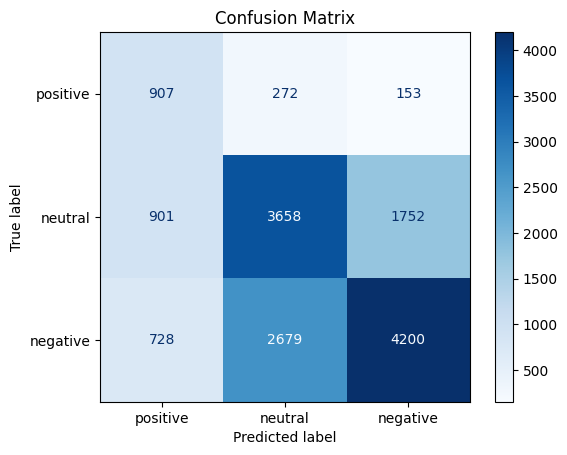

In [93]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = svm_model.predict(X_test_tfidf)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=["positive", "neutral", "negative"])

# Display it with labels
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["positive", "neutral", "negative"])
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

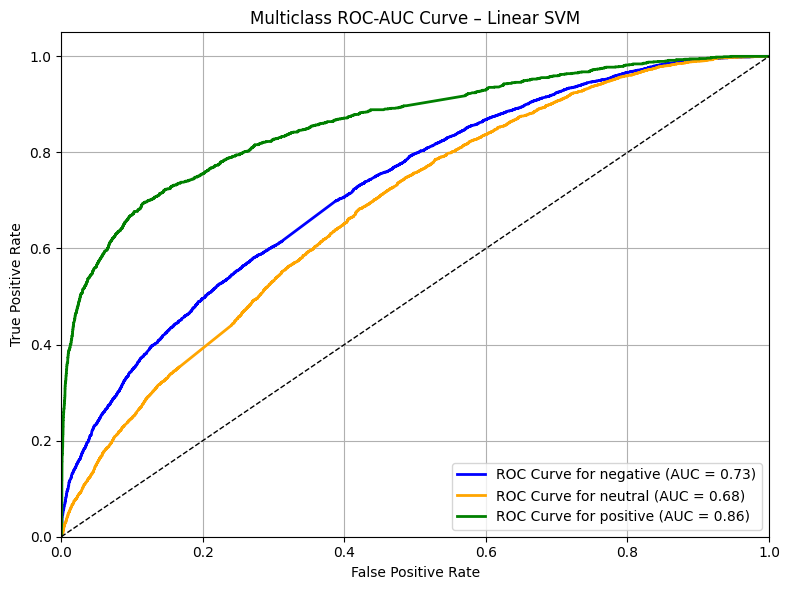

In [94]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve, auc
from itertools import cycle
import numpy as np

# Encode labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train_bal)
y_test_encoded = label_encoder.transform(y_test)
classes = label_encoder.classes_

# Binarize labels for ROC-AUC (One-vs-Rest)
y_train_bin = label_binarize(y_train_encoded, classes=[0, 1, 2])
y_test_bin = label_binarize(y_test_encoded, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# Train One-vs-Rest SVM using LinearSVC + probability calibration
base_svc = LinearSVC(class_weight='balanced', max_iter=1000)
calibrated_svc = CalibratedClassifierCV(base_svc, method='sigmoid', cv=3)
svm_ovr = OneVsRestClassifier(calibrated_svc, n_jobs=-1)
svm_ovr.fit(X_train_tfidf, y_train_bin)

# Predict probabilities
y_score = svm_ovr.predict_proba(X_test_tfidf)

# ROC curve and AUC
fpr, tpr, roc_auc = {}, {}, {}
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC-AUC
colors = cycle(['blue', 'orange', 'green'])
plt.figure(figsize=(8, 6))
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC Curve for {classes[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC-AUC Curve – Linear SVM')
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

# Multinomial Naive-Bayes

📊 Validation Accuracy (Naive Bayes): 0.5737425404944586
📄 Validation Report:
               precision    recall  f1-score   support

    negative       0.66      0.66      0.66      7607
     neutral       0.56      0.45      0.50      6310
    positive       0.35      0.66      0.46      1332

    accuracy                           0.57     15249
   macro avg       0.52      0.59      0.54     15249
weighted avg       0.59      0.57      0.58     15249

📊 Test Accuracy (Naive Bayes): 0.5744918032786885
📄 Test Report:
               precision    recall  f1-score   support

    negative       0.66      0.66      0.66      7607
     neutral       0.57      0.45      0.51      6311
    positive       0.33      0.63      0.43      1332

    accuracy                           0.57     15250
   macro avg       0.52      0.58      0.53     15250
weighted avg       0.59      0.57      0.58     15250



C:\Users\Administrator\AppData\Local\Temp\ipykernel_11560\3731385263.py:26: UserWarning: Glyph 129534 (\N{RECEIPT}) missing from current font.
  plt.tight_layout()
C:\Users\Administrator\anaconda3\envs\pytorchCU126_py310_new\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129534 (\N{RECEIPT}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


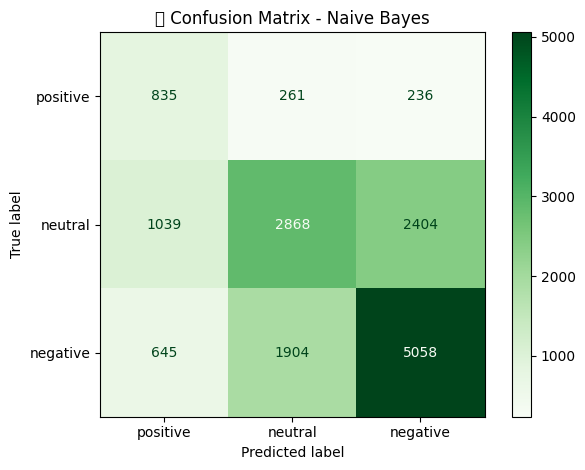

In [95]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- Train Multinomial Naive Bayes ---
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train_bal)

# --- Validation Evaluation ---
y_val_pred = nb_model.predict(X_val_tfidf)
val_acc = accuracy_score(y_val, y_val_pred)
print("📊 Validation Accuracy (Naive Bayes):", val_acc)
print("📄 Validation Report:\n", classification_report(y_val, y_val_pred))

# --- Test Evaluation ---
y_test_pred = nb_model.predict(X_test_tfidf)
test_acc = accuracy_score(y_test, y_test_pred)
print("📊 Test Accuracy (Naive Bayes):", test_acc)
print("📄 Test Report:\n", classification_report(y_test, y_test_pred))

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_test_pred, labels=["positive", "neutral", "negative"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["positive", "neutral", "negative"])
disp.plot(cmap=plt.cm.Greens)
plt.title("🧾 Confusion Matrix - Naive Bayes")
plt.tight_layout()
plt.show()


# Label Encoding & Keras Tokenization & Bengali Dataset Class

In [120]:
# 1. Label Encoding
y_train_encoded = label_encoder.fit_transform(y_train_bal)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)
print(label_encoder.classes_)

# 2. Tokenization & Padding
keras_tokenizer = Tokenizer(num_words=30000, oov_token="<unk>")
keras_tokenizer.fit_on_texts(X_train_bal_clean)

X_train_seq = keras_tokenizer.texts_to_sequences(X_train_bal_clean)
X_val_seq = keras_tokenizer.texts_to_sequences(X_val_clean)
X_test_seq = keras_tokenizer.texts_to_sequences(X_test_clean)

max_len = 100
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=max_len, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post', truncating='post')


['negative' 'neutral' 'positive']


In [122]:
# Dataset Class
class BengaliDataset(Dataset):
    def __init__(self, padded_sequences, labels):
        self.sequences = torch.tensor(padded_sequences, dtype=torch.long)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.labels[idx]

train_loader = DataLoader(BengaliDataset(X_train_pad, y_train_encoded), batch_size=64, shuffle=True)
val_loader = DataLoader(BengaliDataset(X_val_pad, y_val_encoded), batch_size=64)
test_loader = DataLoader(BengaliDataset(X_test_pad, y_test_encoded), batch_size=64)

# Bi-LSTM model

In [108]:
# # 3. Load FastText Embeddings
# from gensim.models import KeyedVectors
# fasttext_model = KeyedVectors.load_word2vec_format("cc.bn.300.vec")

# fasttext_model.save("cc.bn.300.kv")
# print("✅ FastText model saved in .kv format")

In [121]:
# Much faster than reloading .vec every time
fasttext_model = KeyedVectors.load("cc.bn.300.kv")

embedding_dim = 300
vocab_size = len(keras_tokenizer.word_index) + 1
embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, idx in keras_tokenizer.word_index.items():
    if word in fasttext_model:
        embedding_matrix[idx] = fasttext_model[word]
    else:
        embedding_matrix[idx] = np.random.normal(scale=0.6, size=(embedding_dim,))

In [123]:
# 5. BiLSTM Model with Pretrained Embedding
class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_dim=256, output_dim=3, freeze=False):
        super(BiLSTMClassifier, self).__init__()
        num_embeddings, embedding_dim = embedding_matrix.shape
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float32),
            freeze=freeze,
            padding_idx=0
        )
        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True, num_layers=2)
        self.dropout = nn.Dropout(0.5)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        x = self.embedding(x)
        _, (hidden, _) = self.bilstm(x)
        hidden_cat = torch.cat((hidden[-2], hidden[-1]), dim=1)
        x = self.dropout(hidden_cat)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [124]:
# 6. Train & Evaluate Model
import os
model = BiLSTMClassifier(embedding_matrix, hidden_dim=256, output_dim=3, freeze=False)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 50
best_acc = 0.0

os.makedirs("Bi-LSTM Models", exist_ok=True)

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    print(f"Validation Accuracy: {acc:.4f}")
    print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

    if acc > best_acc:
        best_acc = acc
        torch.save(model.state_dict(), "Bi-LSTM Models/best_bilstm_model.pth")
        print("✅ Best model saved")


Epoch 1 | Train Loss: 0.6782
Validation Accuracy: 0.7738
              precision    recall  f1-score   support

    negative       0.89      0.72      0.80      7607
     neutral       0.72      0.83      0.77      6310
    positive       0.60      0.80      0.69      1332

    accuracy                           0.77     15249
   macro avg       0.74      0.79      0.75     15249
weighted avg       0.79      0.77      0.78     15249

✅ Best model saved
Epoch 2 | Train Loss: 0.4150
Validation Accuracy: 0.7789
              precision    recall  f1-score   support

    negative       0.84      0.80      0.82      7607
     neutral       0.77      0.75      0.76      6310
    positive       0.60      0.82      0.69      1332

    accuracy                           0.78     15249
   macro avg       0.73      0.79      0.75     15249
weighted avg       0.79      0.78      0.78     15249

✅ Best model saved
Epoch 3 | Train Loss: 0.2786
Validation Accuracy: 0.7703
              precision    re

In [125]:
# Load best model from the folder
model.load_state_dict(torch.load("Bi-LSTM Models/best_bilstm_model.pth"))
model.to(device)
model.eval()

BiLSTMClassifier(
  (embedding): Embedding(45751, 300, padding_idx=0)
  (bilstm): LSTM(300, 256, num_layers=2, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=512, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=3, bias=True)
)

In [126]:
#7. Test set evaluation
model.eval()
test_preds, test_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

print("🔍 Test Set Evaluation:")
print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))


🔍 Test Set Evaluation:
              precision    recall  f1-score   support

    negative       0.83      0.80      0.82      7607
     neutral       0.76      0.74      0.75      6311
    positive       0.59      0.83      0.69      1332

    accuracy                           0.78     15250
   macro avg       0.73      0.79      0.75     15250
weighted avg       0.78      0.78      0.78     15250



# CNN Text Classification with PyTorch – Full Pipeline

In [52]:
#2. CNN Model for Text Classification
class CNNTextClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, output_dim=3, kernel_sizes=[3,4,5], num_filters=100, dropout=0.5):
        super(CNNTextClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.convs = nn.ModuleList([
            nn.Conv2d(1, num_filters, (k, embedding_dim)) for k in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(kernel_sizes), output_dim)

    def forward(self, x):
        embedded = self.embedding(x)              # (batch_size, seq_len, embed_dim)
        embedded = embedded.unsqueeze(1)          # (batch_size, 1, seq_len, embed_dim)

        conved = [F.relu(conv(embedded)).squeeze(3) for conv in self.convs]  # [(batch_size, num_filters, ~), ...]

        pooled = [F.max_pool1d(c, c.shape[2]).squeeze(2) for c in conved]   # [(batch_size, num_filters), ...]

        cat = torch.cat(pooled, dim=1)            # (batch_size, num_filters * len(kernel_sizes))
        return self.fc(self.dropout(cat))

In [55]:
#4. Training & Validation Loop
import os
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vocab_size = len(keras_tokenizer.word_index) + 1
model = CNNTextClassifier(vocab_size=vocab_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 30
best_acc = 0.0
os.makedirs("CNN Models", exist_ok=True)

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

    # Validation
    model.eval()
    val_preds, val_labels = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(val_labels, val_preds)
    print(f"Validation Accuracy: {acc:.4f}")
    print(classification_report(val_labels, val_preds, target_names=label_encoder.classes_))

    if acc > best_acc:
        best_acc = acc
        save_path = os.path.join(model_dir, "best_cnn_model.pth")
        torch.save(model.state_dict(), save_path)
        print("✅ Best CNN model saved!")


Epoch 1 | Train Loss: 0.9229
Validation Accuracy: 0.6895
              precision    recall  f1-score   support

    negative       0.75      0.84      0.79      2122
     neutral       0.50      0.48      0.49       957
    positive       0.75      0.53      0.62       802

    accuracy                           0.69      3881
   macro avg       0.67      0.62      0.64      3881
weighted avg       0.69      0.69      0.68      3881

✅ Best CNN model saved!
Epoch 2 | Train Loss: 0.7029
Validation Accuracy: 0.6988
              precision    recall  f1-score   support

    negative       0.85      0.74      0.79      2122
     neutral       0.50      0.60      0.55       957
    positive       0.63      0.70      0.66       802

    accuracy                           0.70      3881
   macro avg       0.66      0.68      0.67      3881
weighted avg       0.72      0.70      0.71      3881

✅ Best CNN model saved!
Epoch 3 | Train Loss: 0.5557
Validation Accuracy: 0.7251
              preci

In [56]:
#5. Test set evaluation
# Load best CNN model
model.load_state_dict(torch.load("CNN Models/best_cnn_model.pth"))
model.to(device)
model.eval()

test_preds, test_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

print("🧪 Test Set Evaluation:")
print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))


🧪 Test Set Evaluation:
              precision    recall  f1-score   support

    negative       0.87      0.79      0.83      2123
     neutral       0.58      0.64      0.61       957
    positive       0.66      0.73      0.69       801

    accuracy                           0.74      3881
   macro avg       0.70      0.72      0.71      3881
weighted avg       0.75      0.74      0.74      3881



# Pipeline for CNN + Bi-LSTM Hybrid (PyTorch)

In [45]:
#1. Model Definition
class CNN_BiLSTM_Hybrid(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, output_dim=3, dropout=0.5, embedding_weights=None):
        super(CNN_BiLSTM_Hybrid, self).__init__()

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(embedding_weights, dtype=torch.float32),
                freeze=True,
                padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.conv1 = nn.Conv1d(in_channels=embedding_dim, out_channels=128, kernel_size=5)
        self.pool = nn.MaxPool1d(kernel_size=2)

        self.bilstm = nn.LSTM(input_size=128, hidden_size=hidden_dim, batch_first=True, bidirectional=True)

        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        x = self.embedding(x)                      # (batch_size, seq_len, embedding_dim)
        x = x.permute(0, 2, 1)                     # (batch_size, embedding_dim, seq_len) for Conv1D
        x = F.relu(self.conv1(x))                 # (batch_size, out_channels, new_seq_len)
        x = self.pool(x)                          # (batch_size, out_channels, pooled_len)
        x = x.permute(0, 2, 1)                    # (batch_size, pooled_len, out_channels)
        _, (hidden, _) = self.bilstm(x)           # hidden: (2, batch, hidden_dim)
        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)  # (batch_size, hidden_dim*2)
        x = self.dropout(hidden)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [49]:
#5. Training + Validation Loop
import os
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vocab_size = len(keras_tokenizer.word_index) + 1
model = CNN_BiLSTM_Hybrid(vocab_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 30
best_acc = 0.0
os.makedirs("CNN_BiLSTM_Models", exist_ok=True)

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

    # Validation
    model.eval()
    val_preds, val_labels = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(val_labels, val_preds)
    print(f"Validation Accuracy: {acc:.4f}")
    print(classification_report(val_labels, val_preds, target_names=label_encoder.classes_))

    if acc > best_acc:
        best_acc = acc
        save_path = os.path.join(model_dir, "best_cnn_bilstm_model.pth")
        torch.save(model.state_dict(), save_path)
        print("✅ Best hybrid model saved.")

Epoch 1 | Train Loss: 0.8715
Validation Accuracy: 0.6908
              precision    recall  f1-score   support

    negative       0.80      0.77      0.78      2122
     neutral       0.50      0.57      0.53       957
    positive       0.67      0.63      0.65       802

    accuracy                           0.69      3881
   macro avg       0.66      0.66      0.66      3881
weighted avg       0.70      0.69      0.69      3881

✅ Best hybrid model saved.
Epoch 2 | Train Loss: 0.6315
Validation Accuracy: 0.7202
              precision    recall  f1-score   support

    negative       0.87      0.74      0.80      2122
     neutral       0.53      0.70      0.60       957
    positive       0.67      0.69      0.68       802

    accuracy                           0.72      3881
   macro avg       0.69      0.71      0.70      3881
weighted avg       0.75      0.72      0.73      3881

✅ Best hybrid model saved.
Epoch 3 | Train Loss: 0.4502
Validation Accuracy: 0.7333
             

In [50]:
#6. Test set evaluation
# Load best CNN BiLSTM model
model.load_state_dict(torch.load("CNN_BiLSTM_Models/best_cnn_bilstm_model.pth"))
model.to(device)
model.eval()

test_preds, test_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

print("🧪 Test Set Evaluation:")
print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))


🧪 Test Set Evaluation:
              precision    recall  f1-score   support

    negative       0.86      0.80      0.83      2123
     neutral       0.59      0.56      0.57       957
    positive       0.62      0.77      0.68       801

    accuracy                           0.73      3881
   macro avg       0.69      0.71      0.70      3881
weighted avg       0.74      0.73      0.74      3881



# Bi-LSTM + Attention Model in Keras

In [ ]:
#1. Model Definition (Bi-LSTM + Attention)
class BiLSTM_Attention(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, output_dim=3, dropout=0.5, embedding_weights=None):
        super(BiLSTM_Attention, self).__init__()

        if embedding_weights is not None:
            self.embedding = nn.Embedding.from_pretrained(
                torch.tensor(embedding_weights, dtype=torch.float32),
                freeze=True,
                padding_idx=0
            )
        else:
            self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.attention = nn.Linear(hidden_dim * 2, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, x):
        embedded = self.embedding(x)                       # (batch_size, seq_len, embedding_dim)
        lstm_out, _ = self.bilstm(embedded)                # (batch_size, seq_len, hidden_dim*2)

        # Attention weights
        attn_weights = torch.tanh(self.attention(lstm_out))  # (batch_size, seq_len, 1)
        attn_weights = torch.softmax(attn_weights, dim=1)    # normalize across seq_len

        # Context vector
        context = torch.sum(attn_weights * lstm_out, dim=1)  # (batch_size, hidden_dim*2)

        x = self.dropout(context)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [46]:
#5. Training + Validation Loop
import os
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vocab_size = len(keras_tokenizer.word_index) + 1
model = BiLSTM_Attention(vocab_size).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 30
best_acc = 0.0
os.makedirs("BiLSTM_Attention_Models", exist_ok=True)

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

    # Validation
    model.eval()
    val_preds, val_labels = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(val_labels, val_preds)
    print(f"Validation Accuracy: {acc:.4f}")
    print(classification_report(val_labels, val_preds, target_names=label_encoder.classes_))

    if acc > best_acc:
        best_acc = acc
        torch.save(model.state_dict(), os.path.join(model_dir, "best_bilstm_attention_model.pth"))
        print("✅ Best attention model saved.")

Epoch 1 | Train Loss: 0.6627
Validation Accuracy: 0.7427
              precision    recall  f1-score   support

    negative       0.80      0.75      0.77      7185
     neutral       0.73      0.73      0.73      6692
    positive       0.57      0.76      0.65      1430

    accuracy                           0.74     15307
   macro avg       0.70      0.75      0.72     15307
weighted avg       0.75      0.74      0.74     15307

✅ Best attention model saved.
Epoch 2 | Train Loss: 0.4257
Validation Accuracy: 0.7774
              precision    recall  f1-score   support

    negative       0.85      0.73      0.79      7185
     neutral       0.73      0.83      0.78      6692
    positive       0.69      0.75      0.72      1430

    accuracy                           0.78     15307
   macro avg       0.76      0.77      0.76     15307
weighted avg       0.79      0.78      0.78     15307

✅ Best attention model saved.
Epoch 3 | Train Loss: 0.3245
Validation Accuracy: 0.7794
       

In [47]:
#6. Test set evaluation
# Load best BiLSTM Attention model
model.load_state_dict(torch.load("BiLSTM_Attention_Models/best_bilstm_attention_model.pth"))
model.to(device)
model.eval()
test_preds, test_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        preds = torch.argmax(outputs, dim=1)
        test_preds.extend(preds.cpu().numpy())
        test_labels.extend(labels.cpu().numpy())

print("🧪 Test Set Evaluation:")
print(classification_report(test_labels, test_preds, target_names=label_encoder.classes_))


🧪 Test Set Evaluation:
              precision    recall  f1-score   support

    negative       0.82      0.80      0.81      7192
     neutral       0.78      0.78      0.78      6774
    positive       0.68      0.76      0.72      1342

    accuracy                           0.79     15308
   macro avg       0.76      0.78      0.77     15308
weighted avg       0.79      0.79      0.79     15308



# An BERT + CNN + Bi-LSTM Hybrid Model (PyTorch)

In [57]:
#1. Model Definition (BERT + CNN + Bi-LSTM)
class BERT_CNN_LSTM(nn.Module):
    def __init__(self, bert_model_name='bert-base-multilingual-cased', hidden_dim=128, output_dim=3, dropout=0.5):
        super(BERT_CNN_LSTM, self).__init__()
        
        self.bert = AutoModel.from_pretrained(bert_model_name)
        self.conv1 = nn.Conv1d(in_channels=self.bert.config.hidden_size, out_channels=128, kernel_size=3, padding=1)
        self.lstm = nn.LSTM(input_size=128, hidden_size=hidden_dim, batch_first=True, bidirectional=True)
        
        self.dropout = nn.Dropout(dropout)
        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.fc2 = nn.Linear(64, output_dim)

    def forward(self, input_ids, attention_mask):
        with torch.no_grad():  # Freeze BERT if needed for faster training
            bert_outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        
        last_hidden_state = bert_outputs.last_hidden_state  # (batch_size, seq_len, hidden_size)
        
        x = last_hidden_state.permute(0, 2, 1)  # (batch_size, hidden_size, seq_len) for CNN
        x = F.relu(self.conv1(x))               # (batch_size, 128, seq_len)
        x = x.permute(0, 2, 1)                  # (batch_size, seq_len, 128) for LSTM
        lstm_out, _ = self.lstm(x)              # (batch_size, seq_len, hidden_dim*2)
        pooled = torch.mean(lstm_out, dim=1)    # (batch_size, hidden_dim*2)
        
        x = self.dropout(pooled)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

In [58]:
#2. Dataset Class
class BERTDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=100):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        encoding = self.tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            truncation=True,
            padding='max_length',
            return_tensors='pt',
            return_attention_mask=True
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }


In [59]:
#3. Prepare Dataloaders

tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')

train_dataset = BERTDataset(X_train_bal_clean, y_train_encoded, tokenizer)
val_dataset   = BERTDataset(X_val_clean, y_val_encoded, tokenizer)
test_dataset  = BERTDataset(X_test_clean, y_test_encoded, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=16)
test_loader  = DataLoader(test_dataset, batch_size=16)


In [61]:
#5. Training + Validation Loop
import os
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = BERT_CNN_LSTM().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=2e-5)
epochs = 30
best_acc = 0.0
os.makedirs("BERT_CNN_LSTM_Models", exist_ok=True)

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for batch in train_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    
    print(f"Epoch {epoch+1} | Train Loss: {total_loss/len(train_loader):.4f}")

    # Validation
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            outputs = model(input_ids, attention_mask)
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    print(f"Validation Accuracy: {acc:.4f}")
    print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))

    # Save best model
    if acc > best_acc:
        best_acc = acc
        torch.save(model.state_dict(), "best_bert_cnn_lstm_model.pth")
        print("✅ Saved best BERT+CNN+LSTM model.")

Epoch 1 | Train Loss: 1.0167
Validation Accuracy: 0.5944
              precision    recall  f1-score   support

    negative       0.75      0.69      0.72      2122
     neutral       0.44      0.37      0.40       957
    positive       0.43      0.61      0.51       802

    accuracy                           0.59      3881
   macro avg       0.54      0.56      0.54      3881
weighted avg       0.61      0.59      0.60      3881

✅ Saved best BERT+CNN+LSTM model.


KeyboardInterrupt: 

In [ ]:
#6. Test set evaluation
model.load_state_dict(torch.load("best_bert_cnn_lstm_model.pth"))
model.to(device)
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        outputs = model(input_ids, attention_mask)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("📊 Test Set Evaluation:")
print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_))
